In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("files/retail_sales_dataset.csv")
df

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100
...,...,...,...,...,...,...,...,...,...
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [4]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [5]:
df.duplicated().sum()

0

In [6]:
df.isna().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [7]:
df["Date"] = pd.to_datetime(df["Date"])
df["year"] = df["Date"].dt.year.astype("Int64")
df['Month'] = pd.to_datetime(df['Date']).dt.month_name()
df['Day_name'] = pd.to_datetime(df['Date']).dt.day_name()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    1000 non-null   int64         
 1   Date              1000 non-null   datetime64[ns]
 2   Customer ID       1000 non-null   object        
 3   Gender            1000 non-null   object        
 4   Age               1000 non-null   int64         
 5   Product Category  1000 non-null   object        
 6   Quantity          1000 non-null   int64         
 7   Price per Unit    1000 non-null   int64         
 8   Total Amount      1000 non-null   int64         
 9   year              1000 non-null   Int64         
dtypes: Int64(1), datetime64[ns](1), int64(5), object(3)
memory usage: 79.2+ KB


In [54]:
bins = [0, 18, 25, 35, 45, 60, 100]
labels = ['0-17', '18-24', '25-34', '35-44', '45-59', '60+']
df['Age_Range'] = pd.cut(df['Age'], bins=bins, labels=labels ,right=False)

In [48]:
number_of_Transaction = df['Transaction ID'].nunique()
number_of_Transaction

1000

In [49]:
number_of_Customers = df['Customer ID'].nunique()
number_of_Customers

1000

In [14]:
product_category = df['Product Category'].nunique()
product_category

3

In [50]:
Total_sales = df['Total Amount'].sum()
Total_sales

456000

In [52]:
Avg_sales = df['Total Amount'].mean()
Avg_sales

456.0

In [53]:
total_quantity_sold = df['Quantity'].sum()
total_quantity_sold

2514

In [17]:
Sales_over_year = df.groupby('year')['Total Amount'].sum()
Sales_over_year

year
2023    454470
2024      1530
Name: Total Amount, dtype: int64

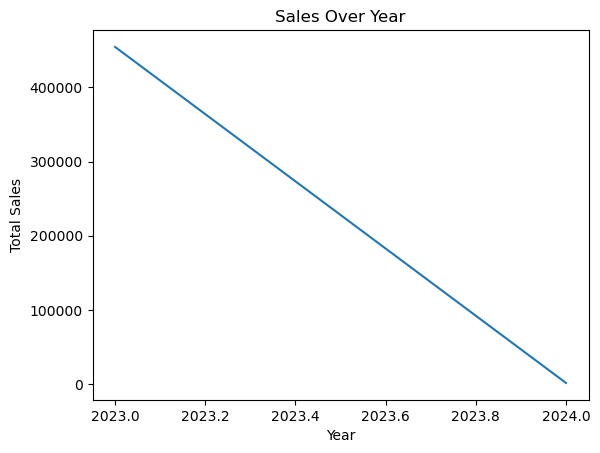

In [66]:
Sales_over_year.plot(kind="line" , title="Sales Over Year")
plt.ylabel("Total Sales")
plt.xlabel("Year")
plt.savefig("images/sales_over_year.png",
            dpi=300, bbox_inches="tight")

In [19]:
Sales_over_month = df.groupby(['year' , 'Month'])['Total Amount'].sum()
Sales_over_month

year  Month    
2023  April        33870
      August       36960
      December     44690
      February     44060
      January      35450
      July         35465
      June         36715
      March        28990
      May          53150
      November     34920
      October      46580
      September    23620
2024  January       1530
Name: Total Amount, dtype: int64

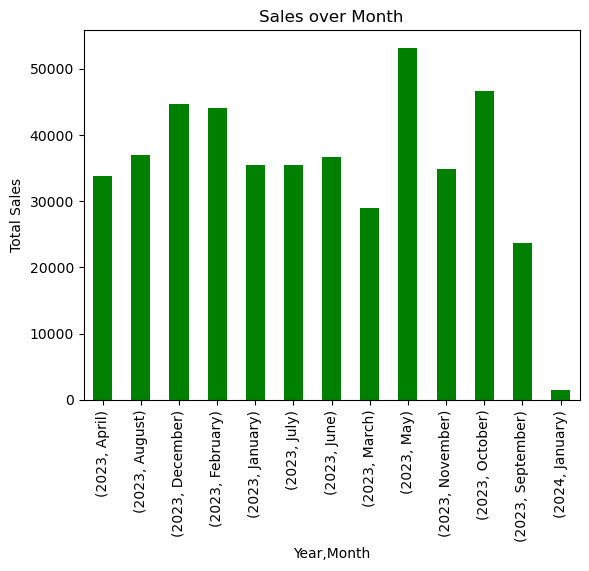

In [67]:
Sales_over_month.plot(kind="bar" , title="Sales over Month" , color='green')
plt.xlabel("Year,Month")
plt.ylabel("Total Sales")
plt.savefig("images/sales_over_month.png",
            dpi=300, bbox_inches="tight")

In [37]:
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
        'Friday', 'Saturday', 'Sunday']

df['Day_name'] = pd.Categorical(
    df['Day_name'],
    categories=days,
    ordered=True
)

Sales_over_week = df.groupby(
    'Day_name', observed=True
)['Total Amount'].sum().sort_index()


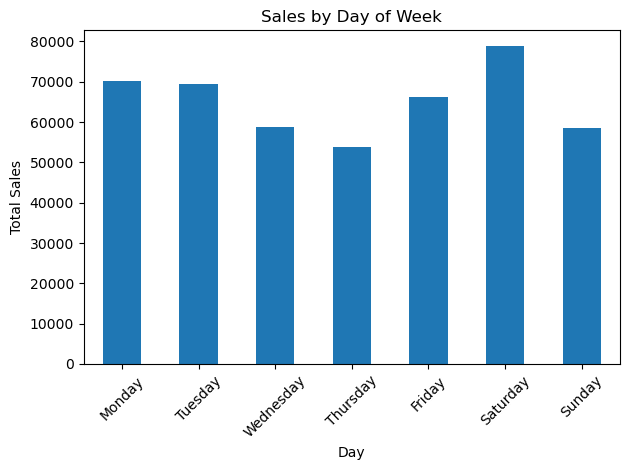

In [68]:
Sales_over_week.plot(kind='bar', title='Sales by Day of Week')
plt.xlabel('Day')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("images/sales_by_dayname.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [41]:
Sales_by_category = df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=True)
Sales_by_category

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64

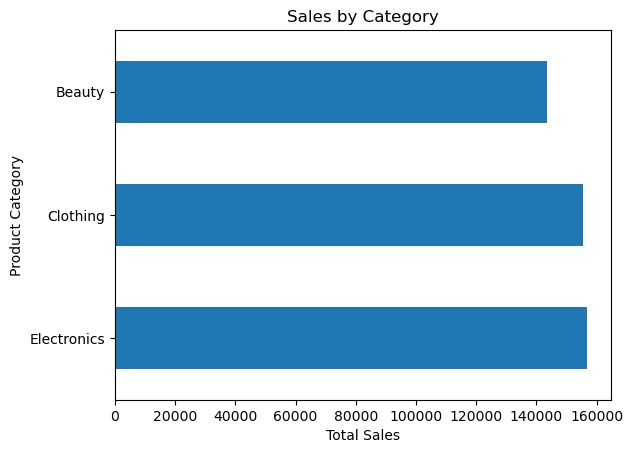

In [69]:
Sales_by_category.plot(kind="barh" , title="Sales by Category")
plt.ylabel("Product Category")
plt.xlabel("Total Sales")
plt.gca().invert_yaxis()
plt.savefig("images/sales_by_category.png",
            dpi=300, bbox_inches="tight")

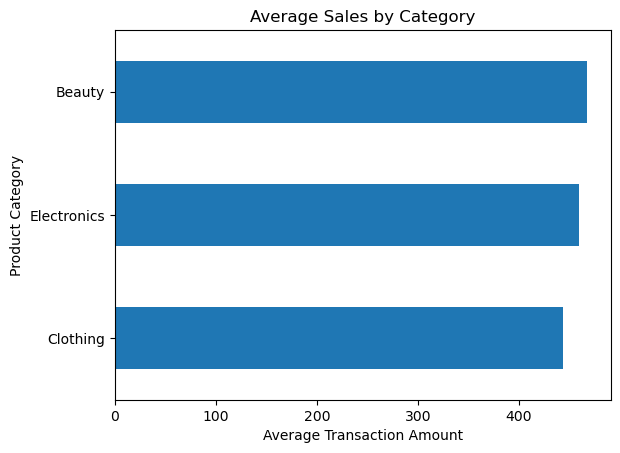

In [45]:
avg_by_category = df.groupby('Product Category')['Total Amount'].mean()
avg_by_category.sort_values().plot(
    kind='barh', title='Average Sales by Category'
)
plt.xlabel('Average Transaction Amount')
plt.show()

In [34]:
Sales_over_gender = df.groupby('Gender')['Total Amount'].sum()
Sales_over_gender

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64

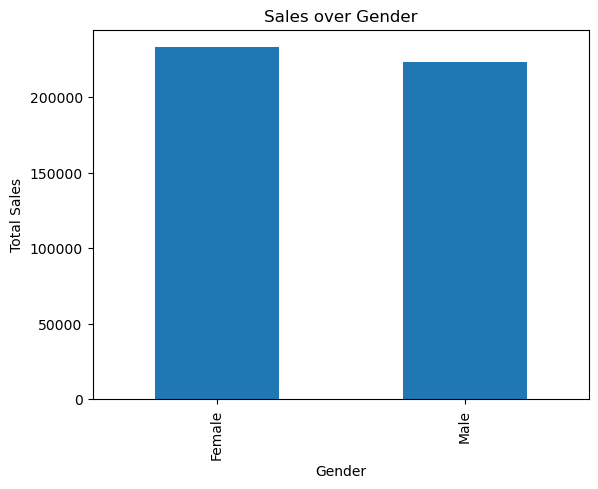

In [73]:
Sales_over_gender.plot(kind="bar" , title="Sales over Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.savefig("images/sales_by_gender.png",
            dpi=300, bbox_inches="tight")

In [55]:
Sales_over_ages = df.groupby('Age_Range')['Total Amount'].sum()
Sales_over_ages

Age_Range
0-17          0
18-24     74650
25-34     97090
35-44     96835
45-59    142610
60+       44815
Name: Total Amount, dtype: int64

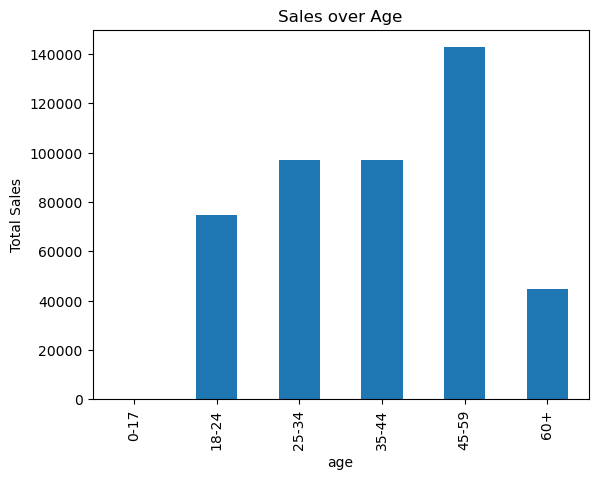

In [70]:
Sales_over_ages.plot(kind="bar" , title="Sales over Age")
plt.ylabel("Total Sales")
plt.xlabel("age")
plt.savefig("images/sales_over_age.png",
            dpi=300, bbox_inches="tight")

In [28]:
Quantity_over_year = df.groupby('year')['Quantity'].sum()
Quantity_over_year

year
2023    2510
2024       4
Name: Quantity, dtype: int64

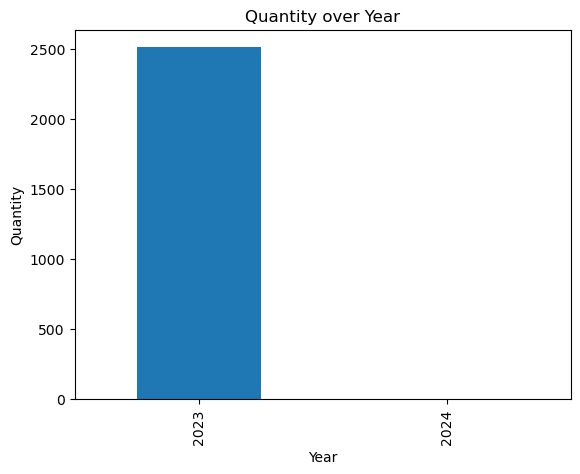

In [71]:
Quantity_over_year.plot(kind="bar" , title="Quantity over Year")
plt.ylabel("Quantity")
plt.xlabel("Year")
plt.savefig("images/quantity_over_year.png",
            dpi=300, bbox_inches="tight")

In [58]:
Quantity_over_month = df.groupby(['year' , 'Month'])['Quantity'].sum()
Quantity_over_month

year  Month    
2023  April        214
      August       227
      December     207
      February     214
      January      195
      July         176
      June         197
      March        194
      May          259
      November     205
      October      252
      September    170
2024  January        4
Name: Quantity, dtype: int64

Text(0, 0.5, 'Quantity')

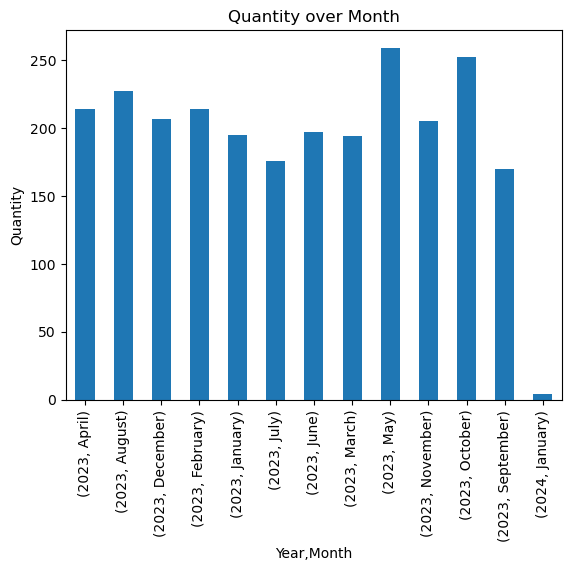

In [59]:
Quantity_over_month.plot(kind="bar" , title="Quantity over Month")
plt.xlabel("Year,Month")
plt.ylabel("Quantity")

In [36]:
Transactions_by_gender = df.groupby('Gender')['Transaction ID'].nunique()
Transactions_by_gender

Gender
Female    510
Male      490
Name: Transaction ID, dtype: int64

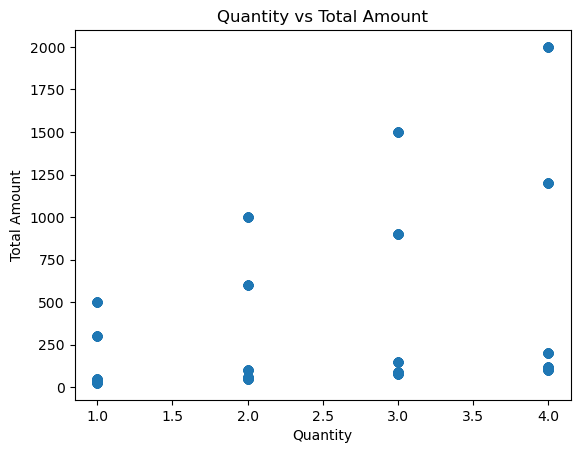

In [44]:
plt.scatter(df['Quantity'], df['Total Amount'])
plt.title('Quantity vs Total Amount')
plt.xlabel('Quantity')
plt.ylabel('Total Amount')
plt.show()

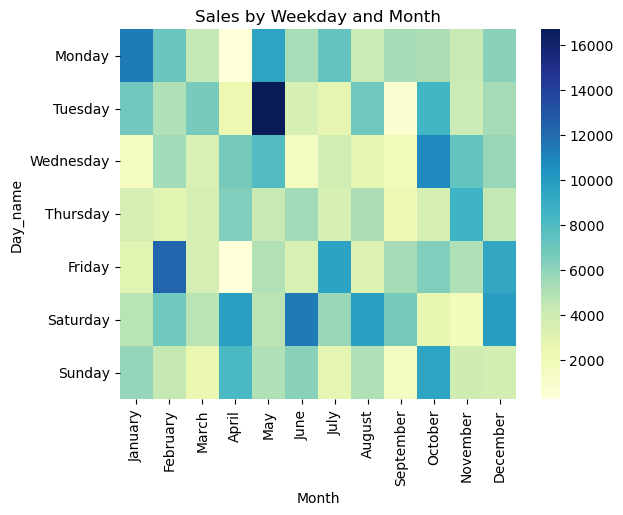

In [72]:
sales_heatmap = df.pivot_table(
    index='Day_name',
    columns='Month',
    values='Total Amount',
    aggfunc='sum',
    observed=False
)

sales_heatmap = sales_heatmap.reindex(columns=[
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
])

sns.heatmap(sales_heatmap, cmap='YlGnBu')
plt.title('Sales by Weekday and Month')
plt.savefig("images/sales_by_weekday_and_month.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [60]:
average_transaction_value = (
    df.groupby('Transaction ID')['Total Amount'].sum().mean()
)
average_transaction_value

456.0

In [61]:
sales_per_customer = df.groupby('Customer ID')['Total Amount'].sum()
sales_per_customer

Customer ID
CUST001     150
CUST002    1000
CUST003      30
CUST004     500
CUST005     100
           ... 
CUST995      30
CUST996      50
CUST997      90
CUST998     100
CUST999     150
Name: Total Amount, Length: 1000, dtype: int64

In [62]:
top_customers = sales_per_customer.sort_values(ascending=False).head(5)
top_customers

Customer ID
CUST487    2000
CUST476    2000
CUST773    2000
CUST503    2000
CUST093    2000
Name: Total Amount, dtype: int64

In [65]:
category_sales_percentage = (
df.groupby('Product Category')['Total Amount'].sum()/ df['Total Amount'].sum() * 100
)
category_sales_percentage

Product Category
Beauty         31.472588
Clothing       34.118421
Electronics    34.408991
Name: Total Amount, dtype: float64